# 02 Modelling, tuning and evaluation

The training itself is the reproducible script `src/train.py`. This notebook **reads its outputs** and explains them; it never refits on the test set.

Protocol (guidelines steps 3 to 7):
1. **Split** by whole seasons in date order: train 2015/16 to 2022/23, validation 2023/24 + 2025, test 2026.
2. **Inputs:** 8 features from the EDA decision table (7 live-state features + dew point), with all preprocessing inside one sklearn `Pipeline`: clip run rates at 36 → median impute → standard scale → model.
3. **Models:** an RRR-only logistic baseline, then logistic regression, KNN, random forest and histogram gradient boosting.
4. **Tuning:** 5-fold `GroupKFold` grouped by match (balls of one match never sit in two folds), using `GridSearchCV` (logreg, KNN) and `RandomizedSearchCV` (RF, boosting), scored by ROC-AUC.
5. **Selection** on validation ROC-AUC, **refit on train+val**, then **one** score on the test season.
6. **Save** the pipeline with joblib (`models/win_pipeline.joblib`) plus `models/meta.json`.

In [1]:
import os, pathlib, sys, json
if pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import joblib
import pandas as pd
from IPython.display import Image, display

table = pd.read_csv("reports/model_comparison_validation.csv")
meta = json.loads(pathlib.Path("models/meta.json").read_text())
print("Selected model:", meta["model"], "| inputs:", meta["feature_columns"])
table.drop(columns="fit_seconds").round(3)

Selected model: logreg | inputs: ['balls_left', 'runs_needed', 'wickets', 'rrr', 'crr', 'runs_last12', 'wkts_last12', 'dew_point_c']


,model,train_auc,cv_auc,val_roc_auc,val_f1,val_log_loss,val_accuracy,best_params
0,baseline_rrr,0.861,NaN,0.885,0.785,0.440,0.806,{}
1,logreg,0.885,0.882,0.912,0.809,0.398,0.825,{'model__C': 0.003}
2,knn,0.904,0.853,0.888,0.782,0.450,0.806,"{'model__n_neighbors': 201, 'model__weights': ..."
3,random_forest,0.917,0.868,0.909,0.773,0.445,0.806,"{'model__n_estimators': 200, 'model__min_sampl..."
4,gradient_boosting,0.905,0.868,0.900,0.760,0.426,0.794,"{'model__min_samples_leaf': 100, 'model__max_l..."


## 1. Model comparison on validation

**Over- and under-fitting:** compare `train_auc`, `cv_auc` and `val_roc_auc`.
- **Logistic regression:** train 0.885 ≈ CV 0.882, so no overfitting. Its validation score is even higher (0.912), because the later seasons happen to be easier to rank.
- **KNN, random forest, boosting:** train AUC is 0.04 to 0.05 above CV, a clear sign of **overfitting** (memorizing matches). Tuning pushed them to their most regularized settings (KNN k=201, boosting depth 2, RF leaf ≥ 50), and even then they do not beat the linear model.
- **Baseline (RRR only):** 0.885. Every tuned model except KNN beats it, so the extra features add real information.

The pattern says the win probability changes **smoothly and mostly monotonically** with the match state (more runs needed means lower, more wickets means lower). That is exactly what logistic regression models, so the simplest model wins.

**Search ranges:** the first run hit grid edges (logreg C=0.01, KNN k=61, boosting leaf=100). The grids were widened and the search re-run. The decision to widen came from CV, not from the test set, and the selected model stayed the same.

## 2. Held-out test season (2026), scored once

In [2]:
pd.DataFrame(meta["test_metrics"]).T.round(3)

,roc_auc,f1,log_loss,accuracy
baseline_rrr,0.892,0.798,0.427,0.765
logreg,0.918,0.839,0.391,0.808


Logistic regression beats the baseline on every metric. On the test season: ROC-AUC 0.918 vs 0.892, log loss 0.391 vs 0.427, F1 0.839 vs 0.798. The test score is close to the validation score (0.912), so the model generalizes to an unseen season, including two franchises that never appeared in training.

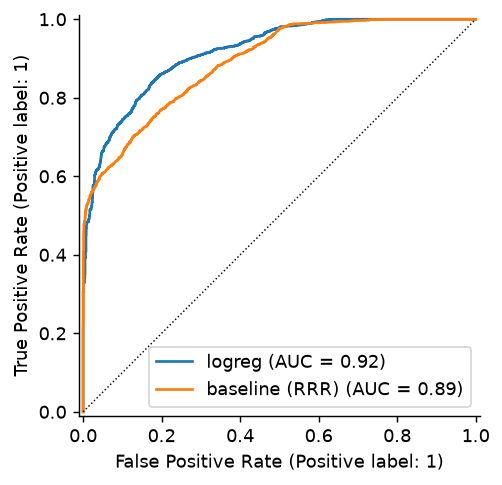

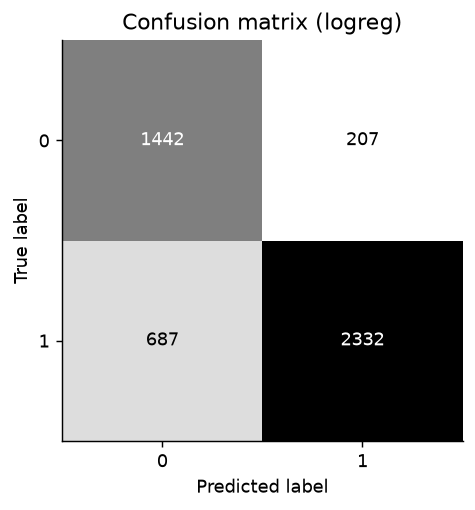

In [3]:
for f in ["eval_roc.png", "eval_confusion.png"]:
    display(Image(filename=f"reports/figures/{f}"))

## 3. Prediction quality by over

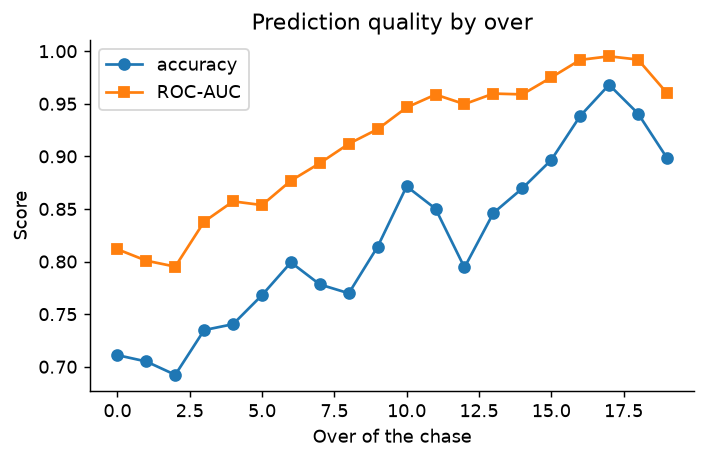

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
over,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000,13.000,14.000,15.000,16.000,17.000,18.000,19.000
accuracy,0.711,0.705,0.692,0.735,0.740,0.768,0.799,0.778,0.770,0.814,0.871,0.850,0.794,0.846,0.870,0.897,0.938,0.968,0.941,0.899
auc,0.812,0.801,0.795,0.838,0.857,0.854,0.877,0.894,0.912,0.926,0.946,0.959,0.950,0.960,0.959,0.975,0.992,0.995,0.992,0.960
rows,263.000,261.000,260.000,264.000,262.000,263.000,254.000,257.000,252.000,253.000,249.000,247.000,248.000,247.000,253.000,232.000,211.000,188.000,135.000,69.000


In [4]:
display(Image(filename="reports/figures/eval_by_over.png"))
pd.read_csv("reports/metrics_by_over.csv").round(3).T

**Pattern:** AUC rises from about 0.80 in the first overs to 0.99 by overs 16 to 18. That is the expected shape: early in a chase the result is genuinely uncertain, and late in the chase the state almost decides it. Errors in the first overs are not a bug; they are the honest uncertainty of a T20 chase.

## 4. Calibration: can the probability be trusted?

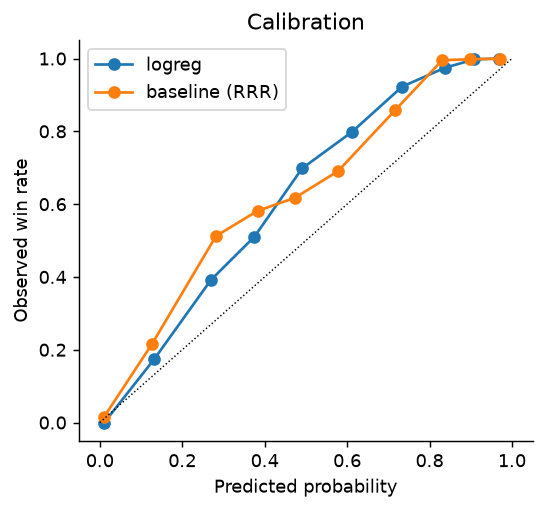

In [5]:
display(Image(filename="reports/figures/eval_calibration.png"))

On the **training** seasons the model is well calibrated: mean prediction 0.548 against 0.548 observed, every bin within 0.05. On the later **validation** and **test** seasons the curve sits **above** the diagonal: chasers win more often than predicted in the mid-range.

That is **era drift**, not a model defect. Scoring rose (average target 167 in train, 183 in validation), so a given required rate is easier to chase now than in 2016. `CalibratedClassifierCV` would re-fit calibration on the same mixed-era folds and could not fix a time trend. Refitting the final model on train+val brings in recent seasons. Recency weighting or retraining each season is listed as future work.

## 5. What the model learned (logistic regression coefficients)

rrr           -1.556
runs_needed   -1.214
wickets       -0.638
wkts_last12   -0.145
dew_point_c   -0.057
runs_last12   -0.019
crr            0.146
balls_left     0.286
dtype: float64

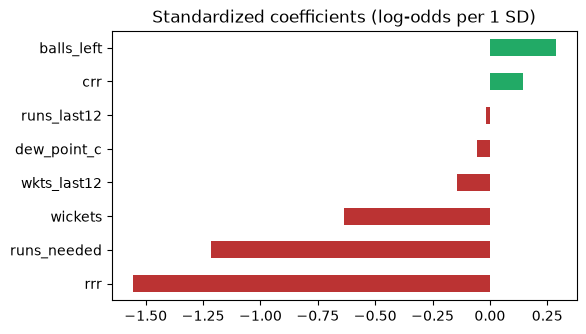

In [6]:
pipe = joblib.load("models/win_pipeline.joblib")
coef = pd.Series(pipe.named_steps["model"].coef_[0], index=meta["feature_columns"]).sort_values()
ax = coef.plot.barh(color=["#b33" if v < 0 else "#2a6" for v in coef], figsize=(6, 3.5),
                    title="Standardized coefficients (log-odds per 1 SD)")
ax.figure.savefig("reports/figures/model_coefficients.png", bbox_inches="tight")
coef.round(3)

Inputs are standardized, so coefficient sizes are comparable: each one is the change in log-odds of a chase win for a one-standard-deviation increase in that feature, with the others held fixed. Negative means it lowers the chaser's chance. The signs match cricket sense. `rrr` (-1.56), `runs_needed` (-1.21) and `wickets` (-0.64) lower the chaser's chance; `balls_left` (+0.29) and `crr` (+0.15) raise it. The momentum features (`runs_last12`, `wkts_last12`) add little once the totals are known. **Dew is about zero (-0.06):** at the resolution we have (a city-wide evening average), the data does not support the belief that dew helps chasers. It stays in the model by the group's decision, so the second data source is used, and its near-zero weight shows the model is not misled by it. This is the simplest possible answer to "why did the model say 70%?", which helps both the viva and the app's explanation.

## 6. Error analysis: the most confident mistakes

In [7]:
pd.read_csv("reports/worst_errors.csv")

,match_id,batting_team,venue,over,runs,wickets,target,y,p_final
0,1527559,Multan Sultans,"Gaddafi Stadium, Lahore",0,0,0,226,1,0.090322
1,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",5,48,3,214,1,0.093594
2,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",5,48,3,214,1,0.098854
3,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",5,48,3,214,1,0.104365
4,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",6,58,3,214,1,0.106997
5,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",6,57,3,214,1,0.108281
6,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",5,48,3,214,1,0.109130
7,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",6,56,3,214,1,0.109543
8,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",6,55,3,214,1,0.110529
9,1527584,Hyderabad Kingsmen,"National Stadium, Karachi",6,54,3,214,1,0.111494


The largest errors are mostly **very high chases that succeeded** (e.g. targets above 210 in 2026), where the model gave the chaser under 10%. Big totals are chased more often in the recent high-scoring era, which matches the drift seen in the calibration plot. Several errors come from the same match, because consecutive balls share the same situation.

**Limitations to report:** era drift in scoring; no player or team-strength information (deliberately dropped because it drifts); weather is only a city-level evening average; and a single 42-match test season.